In [3]:
import numpy as np
import time

def main():
    t0 = time.time()
    cache = np.load("alpha_cache/alpha_cache_g0.npz")
    evecs = cache["valid_evecs"]
    inv_evals = 1.0 / cache["valid_evals"]
    
    N = evecs.shape[0] // 3
    bonds = np.loadtxt("bonds_g0.txt")
    U3_Hinv = np.zeros((N, 3))
    
    for row in bonds:
        i, j = int(row[0]), int(row[1])
        rij = row[2:5]
        D2, D3 = row[6], row[7]
        psi_i = evecs[i*3:i*3+3, :]  # Shape: (3, 11997)
        psi_j = evecs[j*3:j*3+3, :]  # Shape: (3, 11997)
        d_psi = psi_j - psi_i
        C = (d_psi * inv_evals) @ d_psi.T
        f_ij = -(D3 * np.dot(rij, C @ rij) * rij + 
                 D2 * np.trace(C) * rij + 
                 2 * D2 * (C @ rij))
        
        U3_Hinv[i] += f_ij
        U3_Hinv[j] -= f_ij

    output_file = "U3_Hinv_g0.txt"
    np.savetxt(output_file, U3_Hinv, fmt="%.12e", header="U''' : H^-1 vector (Nx3)")  

if __name__ == "__main__":
    main()

Loading data from: nvt_lj_T0.000001_g5.dat


<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_4781/4125185955.py:20: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(filename, sep='\s+', header=None, names=columns)


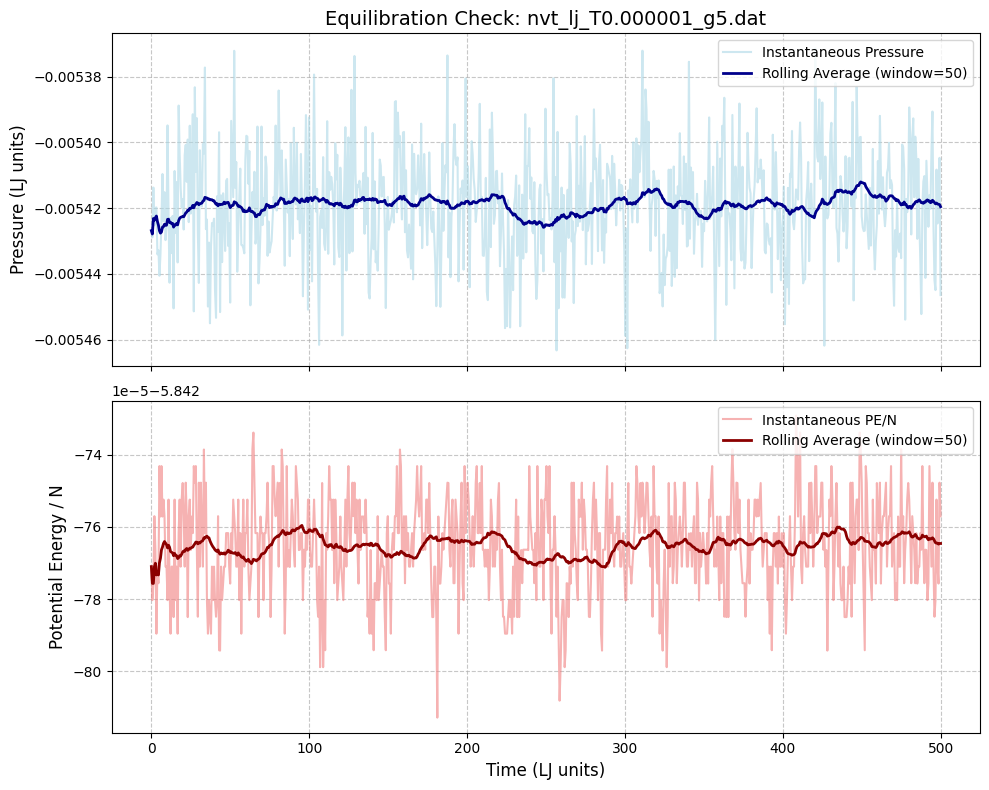

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob
import sys

def analyze_equilibration(filename, window_size=50):
    """
    Reads the NVT simulation output and plots Pressure and PE vs Time
    to visually check if the system is properly equilibrated.
    """
    print(f"Loading data from: {filename}")
    
    # The C code outputs: time, KE/N, PE/N, pressure
    # separated by tabs/spaces.
    columns = ['Time', 'KE_per_N', 'PE_per_N', 'Pressure']
    
    try:
        # FIXED: Using sep='\s+' instead of delim_whitespace=True
        df = pd.read_csv(filename, sep='\s+', header=None, names=columns)
    except FileNotFoundError:
        print(f"Error: Could not find file {filename}")
        return

    # Calculate rolling averages to smooth out the Nosé-Hoover fluctuations
    df['Pressure_Rolling'] = df['Pressure'].rolling(window=window_size, min_periods=1).mean()
    df['PE_Rolling'] = df['PE_per_N'].rolling(window=window_size, min_periods=1).mean()

    # Create the plots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    # --- Plot 1: Pressure vs Time ---
    ax1.plot(df['Time'], df['Pressure'], color='lightblue', alpha=0.6, label='Instantaneous Pressure')
    ax1.plot(df['Time'], df['Pressure_Rolling'], color='darkblue', linewidth=2, label=f'Rolling Average (window={window_size})')
    ax1.set_ylabel('Pressure (LJ units)', fontsize=12)
    ax1.set_title(f'Equilibration Check: {filename}', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.7)
    ax1.legend(loc='upper right')

    # --- Plot 2: Potential Energy vs Time ---
    ax2.plot(df['Time'], df['PE_per_N'], color='lightcoral', alpha=0.6, label='Instantaneous PE/N')
    ax2.plot(df['Time'], df['PE_Rolling'], color='darkred', linewidth=2, label=f'Rolling Average (window={window_size})')
    ax2.set_xlabel('Time (LJ units)', fontsize=12)
    ax2.set_ylabel('Potential Energy / N', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    if len(sys.argv) > 1 and not sys.argv[1].startswith('-'):
        analyze_equilibration(sys.argv[1])
    else:
        dat_files = glob.glob("nvt_lj_T*_g*.dat")
        if not dat_files:
            print("No simulation output files found (looking for nvt_lj_T*_g*.dat).")
        else:
            analyze_equilibration(dat_files[0])

Loading data from: nvt_lj_T0.000010_g0.dat


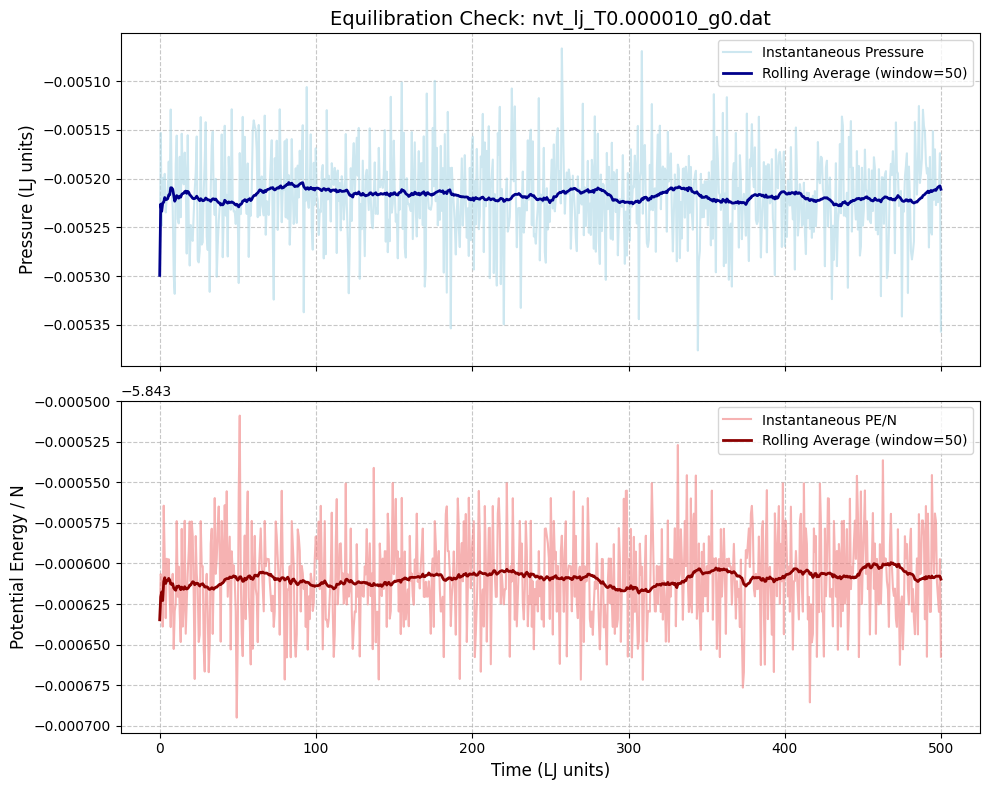

In [8]:
# Call the function directly with your target file
analyze_equilibration("nvt_lj_T0.000010_g0.dat")

Found 100 files. Generating comparative plots...


/tmp/ipykernel_4781/1498753361.py:63: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


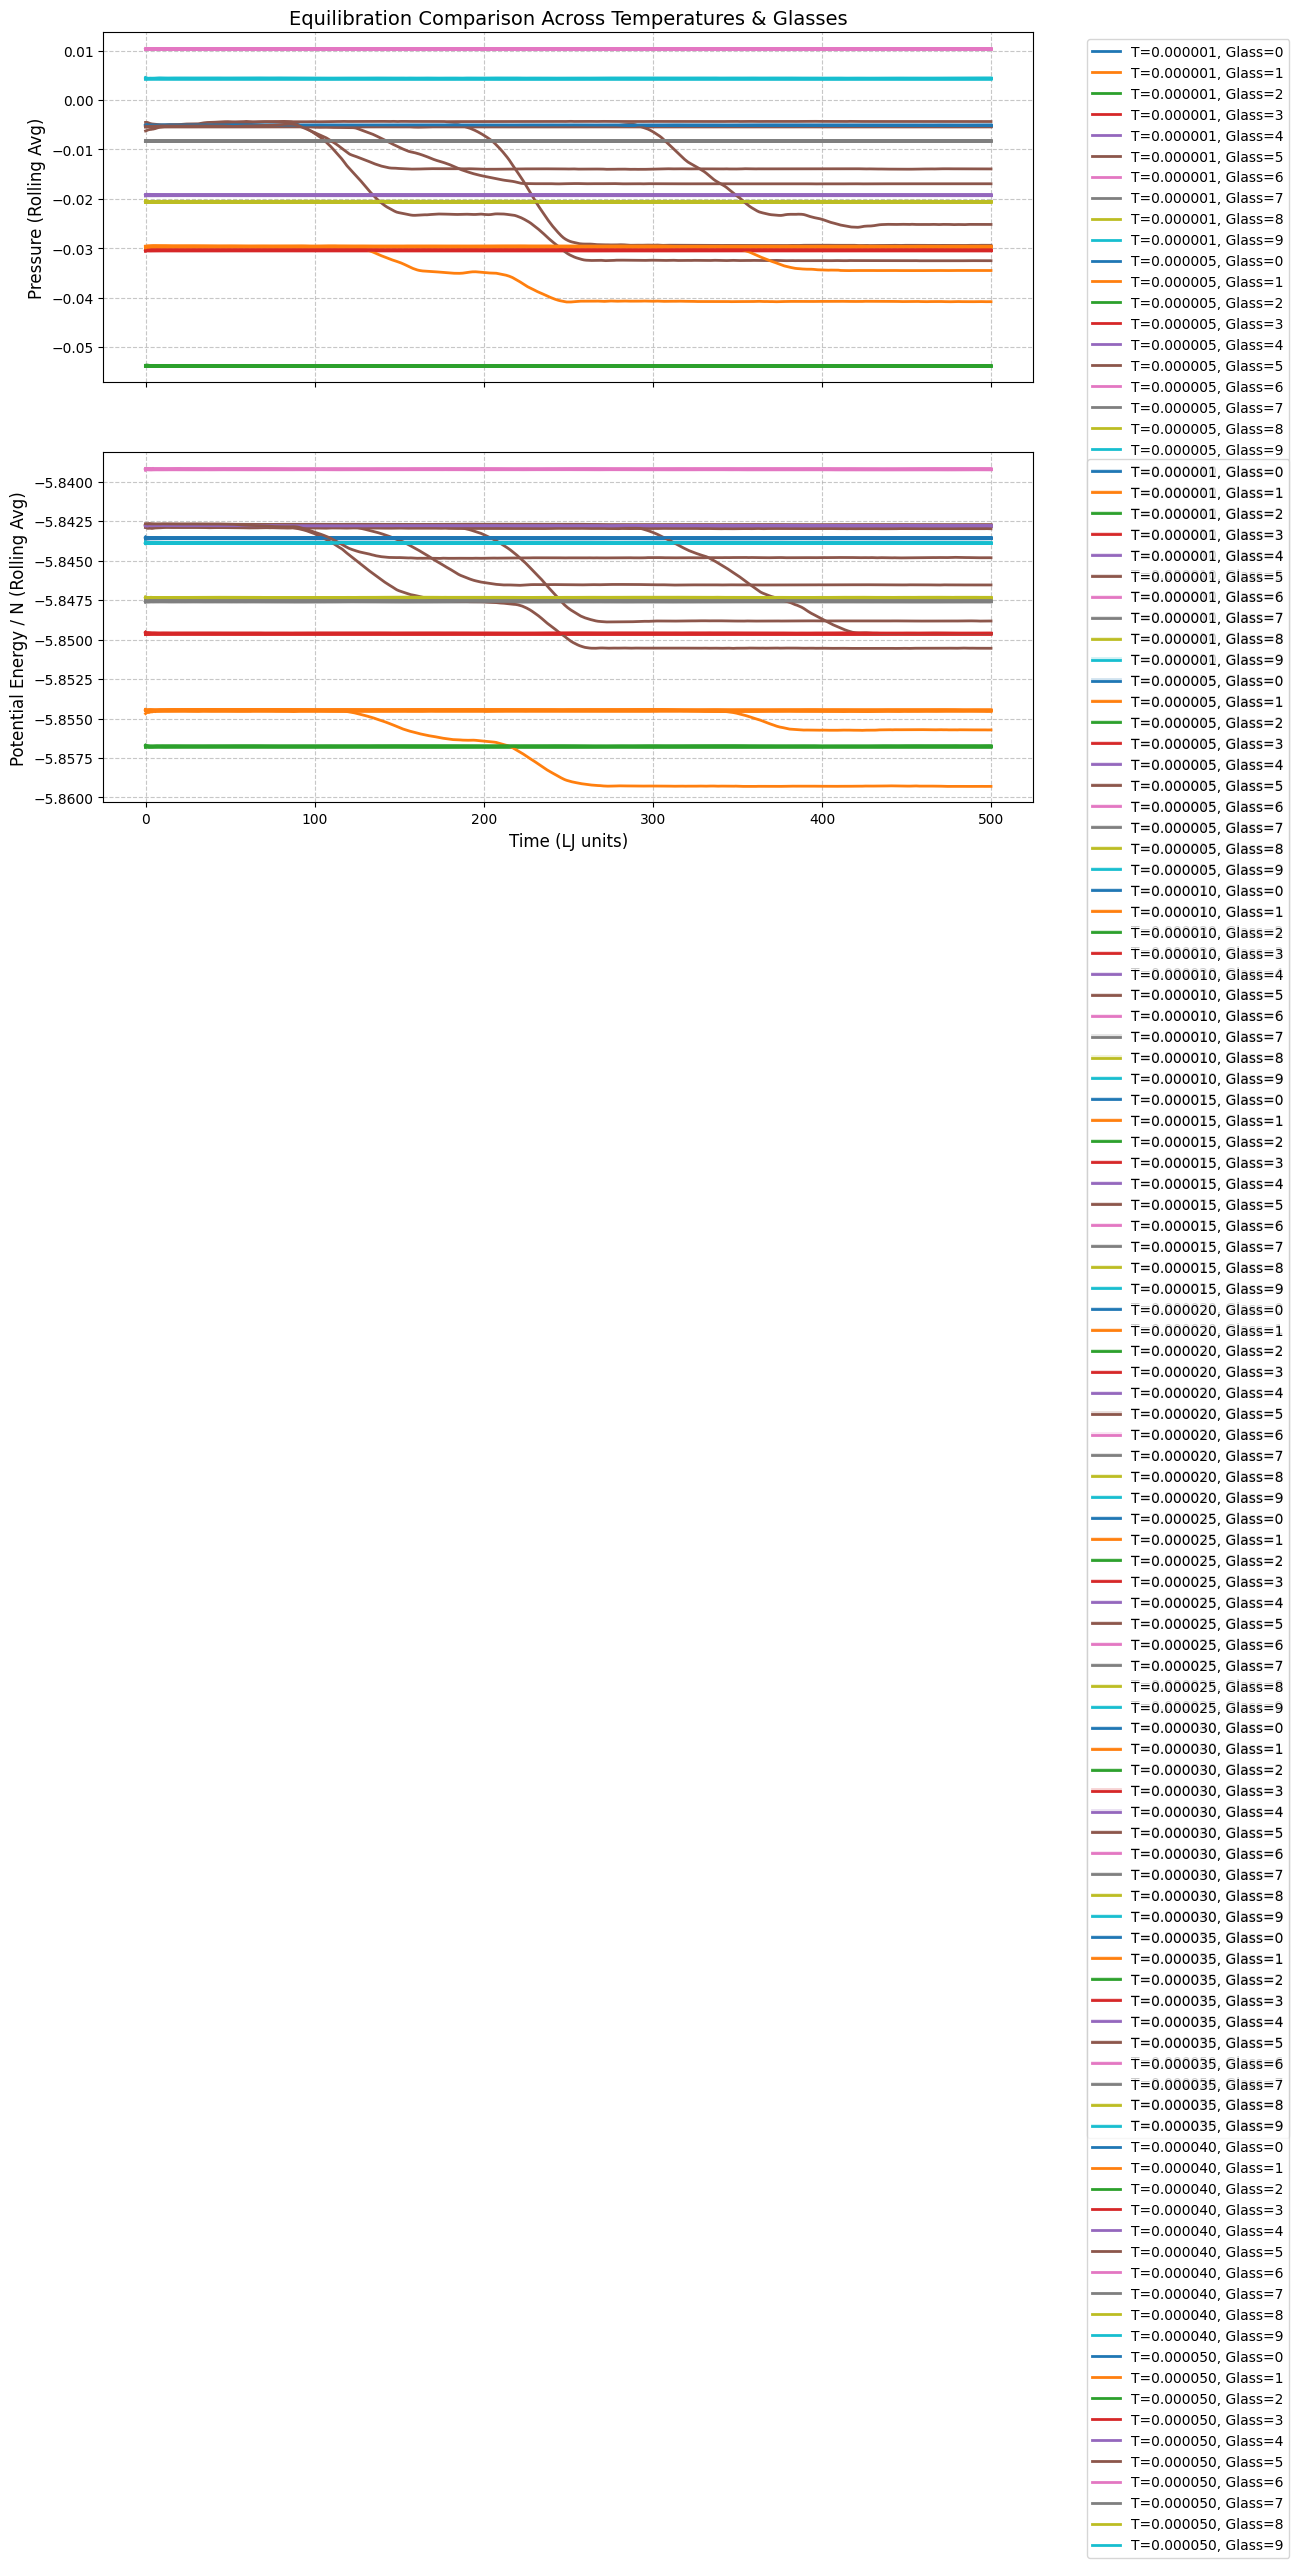

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob
import re

def analyze_multiple_equilibration(window_size=50):
    """
    Finds all NVT simulation outputs, extracts their parameters, 
    and plots their rolling averages together for comparison.
    """
    # 1. Find and sort all matching files in the directory
    file_list = glob.glob("nvt_lj_T*_g*.dat")
    file_list.sort() # Sorts them so your legend is organized (e.g., lowest T to highest)

    if not file_list:
        print("No simulation output files found (looking for nvt_lj_T*_g*.dat).")
        return

    print(f"Found {len(file_list)} files. Generating comparative plots...")

    # Create the plot canvas
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
    columns = ['Time', 'KE_per_N', 'PE_per_N', 'Pressure']

    # 2. Loop through every file found
    for filename in file_list:
        # Extract Temp (T) and Glass ID (g) from the filename for the legend
        # This looks for "T" followed by numbers/decimals, and "g" followed by numbers
        match = re.search(r'T([0-9.]+)_g([0-9]+)', filename)
        if match:
            label = f"T={match.group(1)}, Glass={match.group(2)}"
        else:
            label = filename # Fallback if the filename format is weird

        # 3. Read the data
        try:
            df = pd.read_csv(filename, sep=r'\s+', header=None, names=columns)
        except Exception as e:
            print(f"Could not read {filename}: {e}")
            continue

        # 4. Calculate rolling averages to smooth out thermostat noise
        df['Pressure_Rolling'] = df['Pressure'].rolling(window=window_size, min_periods=1).mean()
        df['PE_Rolling'] = df['PE_per_N'].rolling(window=window_size, min_periods=1).mean()

        # 5. Plot ONLY the rolling averages to keep the comparative graph clean
        ax1.plot(df['Time'], df['Pressure_Rolling'], linewidth=2, label=label)
        ax2.plot(df['Time'], df['PE_Rolling'], linewidth=2, label=label)

    # --- Formatting the Graphs ---
    ax1.set_ylabel('Pressure (Rolling Avg)', fontsize=12)
    ax1.set_title('Equilibration Comparison Across Temperatures & Glasses', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.7)
    # Move legend outside the plot so it doesn't cover your data
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 

    ax2.set_xlabel('Time (LJ units)', fontsize=12)
    ax2.set_ylabel('Potential Energy / N (Rolling Avg)', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

# Run the function
analyze_multiple_equilibration(window_size=50)